# Wind-turbine surrogate — learning the power curve, and its cliff

The wind turbine is our second ODE benchmark. Its controller has **two regimes**: below rated wind
it runs region-II torque control (MPPT), so power rises with $v^3$; above rated wind a pitch loop
**caps** power at the rated $5$ MW to protect the drivetrain. We fit a black-box surrogate
$\hat P_\theta(v)\approx P(v)$ from steady-state solver data in region II, then ask it to predict
region III --- a regime, and a controller action, it has **never seen**. The result is the
extrapolation cliff in physical form: the surrogate keeps extrapolating the cubic rise and predicts
a turbine making $\sim 9$ MW in a storm, while the real machine holds $5$ MW.

### Setup and ground-truth power curve

Import the Chapter-1 **turbine benchmark** (`pyutils.benchmarks.turbine`, the NREL-5MW-like rotor
ODE $J\dot\omega = T_\text{aero}-T_\text{gen}$ under its baseline controller) and build the target
the surrogate must learn: the steady **power curve** $P(v)$. For each of 89 wind speeds
$v\in[v_\text{in},v_\text{out}]=[3,25]$ m/s the benchmark integrates the rotor to steady state and
reads off power. The controller has two regimes, split at the **rated wind speed** $v_\text{rated}$:
* **Region II** ($v<v_\text{rated}$): pitch $\beta=0$, generator torque $T_\text{gen}=K\omega^2$
  tracks $\lambda_\text{opt}$ (MPPT), so $P\propto v^3$;
* **Region III** ($v\ge v_\text{rated}$): torque saturates and a pitch PI loop feathers the blades to
  **cap** power at the rated $P_\text{rated}=5$ MW and protect the drivetrain.

Default parameters: air density $\rho=1.225$ kg/m³, rotor radius $R=63$ m, drivetrain inertia
$J=38.6\times10^6$ kg m². The first cell also plots the curve and the controller state.

v_rated=11.09 m/s   rated power=5.0 MW


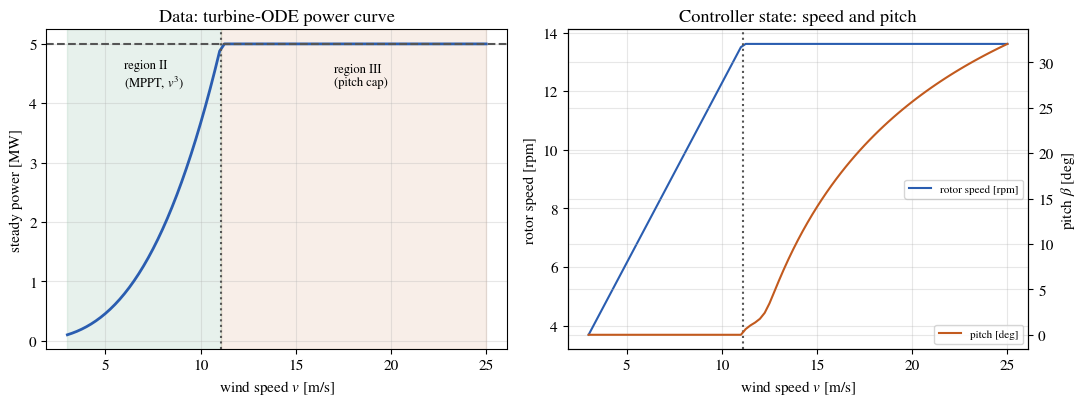

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils.pinn_core import MLP
from pyutils import set_plot_style, save_dual, fg, muted
from pyutils.benchmarks import turbine
torch.set_default_dtype(torch.float64); torch.manual_seed(0); np.random.seed(0)
set_plot_style()
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

# --- ground truth: steady power curve from the turbine rotor ODE + controller ---
p = turbine.TurbineParams(); V_RATED = p.v_rated
vv = np.linspace(p.v_in, p.v_out, 89)
P, OM, BE = turbine.power_curve(vv, p=p)
Pmw = P / 1e6; rpm = OM * 30.0 / np.pi
print(f'v_rated={V_RATED:.2f} m/s   rated power={p.P_rated/1e6:.1f} MW')

# show the data: power curve + the controller's two regions
def plot_ddm_wind_sweep():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].axvspan(p.v_in, V_RATED, color='C2', alpha=0.10)
    ax[0].axvspan(V_RATED, p.v_out, color='C1', alpha=0.10)
    ax[0].plot(vv, Pmw, 'C0', lw=2)
    ax[0].axhline(p.P_rated/1e6, ls='--', color=muted())
    ax[0].axvline(V_RATED, ls=':', color=muted())
    ax[0].text(6.0, 4.3, 'region II\n(MPPT, $v^3$)', fontsize=9)
    ax[0].text(17.0, 4.3, 'region III\n(pitch cap)', fontsize=9)
    ax[0].set(xlabel='wind speed $v$ [m/s]', ylabel='steady power [MW]',
              title='Data: turbine-ODE power curve')
    ax[1].plot(vv, rpm, 'C0', label='rotor speed [rpm]')
    ax2 = ax[1].twinx(); ax2.plot(vv, BE, 'C1', label='pitch [deg]')
    ax[1].axvline(V_RATED, ls=':', color=muted())
    ax[1].set(xlabel='wind speed $v$ [m/s]', ylabel='rotor speed [rpm]',
              title='Controller state: speed and pitch')
    ax2.set_ylabel('pitch $\\beta$ [deg]')
    ax[1].legend(loc='center right', fontsize=8); ax2.legend(loc='lower right', fontsize=8)
    plt.tight_layout()

save_dual(plot_ddm_wind_sweep, 'ddm_wind_sweep', FIG); plt.show()

The print reports **$v_\text{rated}=11.09$ m/s** and the $5.0$ MW rating. Left figure: power rises
cubically through the green region II and flattens exactly at $5$ MW across the orange region III.
Right figure: rotor speed (blue) climbs linearly to $\sim\!13.6$ rpm at rated then holds flat, while
pitch $\beta$ (orange) stays $0°$ in region II and ramps to $\sim\!32°$ across region III — the two
control actions that produce the cap. Leaves the truth arrays `vv`, `Pmw`, `rpm`, `BE` for the fit.

## Train in region II, extrapolate into region III

The split is **in wind speed**. The MLP surrogate $\hat P_\theta(v)\approx P(v)$
(`MLP([1,32,32,1])`, standardized input and target, Adam `lr=3e-3`, 4000 steps, MSE loss) sees
**only region-II data** ($v<v_\text{rated}=11.09$ m/s) minus 4 randomly held-out points. Those 4
held-out region-II points test **interpolation**; the whole of region III ($v\ge v_\text{rated}$)
tests **extrapolation** across the controller's regime change — a regime, and a pitch-capping action,
the network never saw.

final train loss 2.11e-06
RMSE  interpolation (held-out region II) = 0.002 MW
RMSE  extrapolation (region III)         = 3.737 MW
peak surrogate power in region III = 9.3 MW  (true cap = 5.0 MW)


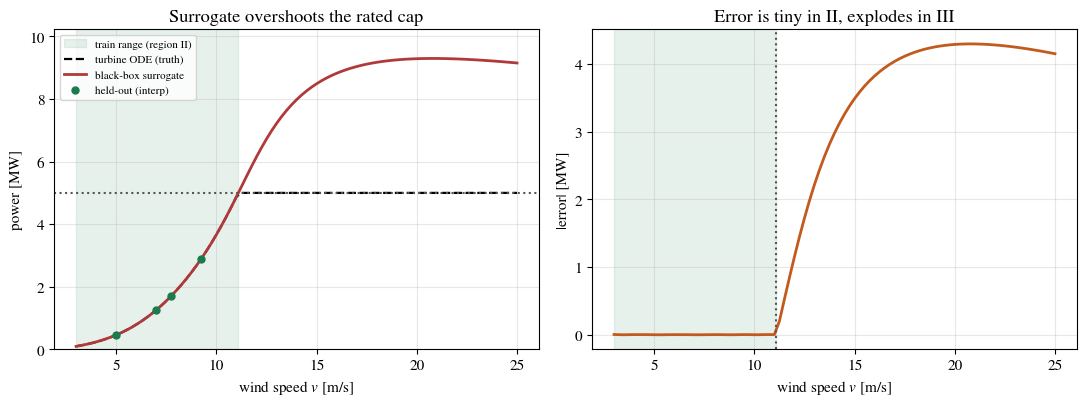

In [2]:
# split by wind speed: train = region II (minus held-out), interp = held-out II, extrap = III
region_II = vv < V_RATED
rng = np.random.default_rng(0)
idx_II = np.where(region_II)[0]
hold = rng.choice(idx_II, size=4, replace=False)          # held-out interpolation points
train_mask = region_II.copy(); train_mask[hold] = False    # region II minus held-out
interp_mask = np.zeros_like(region_II); interp_mask[hold] = True
extrap_mask = ~region_II                                    # region III

vm, vs = vv[train_mask].mean(), vv[train_mask].std()
pm, ps = Pmw[train_mask].mean(), Pmw[train_mask].std()
def to_x(v): return torch.tensor(((np.atleast_1d(v) - vm) / vs).reshape(-1, 1))
Xt = to_x(vv[train_mask]); Yt = torch.tensor(((Pmw[train_mask] - pm) / ps).reshape(-1, 1))

torch.manual_seed(0); net = MLP([1, 32, 32, 1])
opt = torch.optim.Adam(net.parameters(), lr=3e-3)
for ep in range(4000):
    opt.zero_grad(); loss = ((net(Xt) - Yt)**2).mean(); loss.backward(); opt.step()
print('final train loss %.2e' % float(loss.detach()))

def predict(v):
    with torch.no_grad():
        return net(to_x(v)).numpy().ravel() * ps + pm
Pred = predict(vv)

rmse = lambda m: float(np.sqrt(np.mean((Pred[m] - Pmw[m])**2)))
e_interp, e_extrap = rmse(interp_mask), rmse(extrap_mask)
overshoot = Pred[extrap_mask].max()
print(f'RMSE  interpolation (held-out region II) = {e_interp:.3f} MW')
print(f'RMSE  extrapolation (region III)         = {e_extrap:.3f} MW')
print(f'peak surrogate power in region III = {overshoot:.1f} MW  (true cap = {p.P_rated/1e6:.1f} MW)')

def plot_ddm_wind_cliff():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].axvspan(p.v_in, V_RATED, color='C2', alpha=0.10, label='train range (region II)')
    ax[0].plot(vv, Pmw, '--', color=fg(), lw=1.6, label='turbine ODE (truth)')
    ax[0].plot(vv, Pred, 'C3', lw=2, label='black-box surrogate')
    ax[0].scatter(vv[interp_mask], Pmw[interp_mask], color='C2', zorder=5, s=25,
                  label='held-out (interp)')
    ax[0].axhline(p.P_rated/1e6, ls=':', color=muted())
    ax[0].set(xlabel='wind speed $v$ [m/s]', ylabel='power [MW]',
              title='Surrogate overshoots the rated cap', ylim=(0, 1.1*overshoot))
    ax[0].legend(fontsize=8, loc='upper left')
    ax[1].axvspan(p.v_in, V_RATED, color='C2', alpha=0.10)
    ax[1].plot(vv, np.abs(Pred - Pmw), 'C1', lw=2)
    ax[1].axvline(V_RATED, ls=':', color=muted())
    ax[1].set(xlabel='wind speed $v$ [m/s]', ylabel='|error| [MW]',
              title='Error is tiny in II, explodes in III')
    plt.tight_layout()

save_dual(plot_ddm_wind_cliff, 'ddm_wind_cliff', FIG); plt.show()
assert e_extrap > 5 * e_interp        # extrapolation error dwarfs interpolation
assert overshoot > 1.4 * p.P_rated/1e6  # surrogate blows past the physical cap

The surrogate fits region II almost exactly — **interpolation RMSE $0.002$ MW** on the held-out
points (final train loss $2.1\times10^{-6}$) — then, never having seen the pitch cap, it
**extrapolates the cubic rise straight past $5$ MW**, peaking at **9.3 MW** near $v\approx20$ m/s
against the true $5.0$ MW cap. The **extrapolation RMSE is $3.74$ MW**, roughly $1800\times$ the
interpolation error; the right panel is flat at zero in region II and explodes to $\sim\!4.3$ MW in
region III. Both asserts (extrap $>5\times$ interp; overshoot $>1.4\times$ rated) pass. The failure
is a missing *mechanism* — the pitch controller — not missing data.

**Lesson.** In region II the surrogate is excellent, and inference is a single forward pass ---
far cheaper than integrating the rotor ODE. But it has no knowledge of the pitch controller that
caps power in region III, so it extrapolates the cubic rise straight past the rated limit,
predicting power the machine will never (and must never) produce. No amount of region-II data fixes
this: the failure is a missing *mechanism*, not missing data. Keeping the physics --- the torque
balance and the controller --- and learning only the uncertain aerodynamics ($C_p$) is the hybrid
route that makes the surrogate trustworthy across both regimes. **This is the case for HAM.**